# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv') 

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- En users hay valores nulos en las columnas city 11.72% y churn_Date 88.35%
- En usage hay valores nulos en las columnas date .125%, duration 55.19% y lenght 44.74%
- Indica qué harías: ¿imputar, eliminar, ignorar?
- En users, la columna city la dejaria como una categoria "unknow" y churn_date la dejaria igual ya que el valor nulo significa activo
- en usage, la columna date la imputaria y la columna duration y lenght las dejaria los valores nulos por que representan informacion importante 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
users["age"].describe()

count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

- La columna `user_id` es un identificador, las estadisticas no son interpretables
- La columna `age` el promedio y la mediana difieren, el promedio se va para abajo por el minimo, hay outliers en min ya que -999 no es una edad 

In [13]:
usage[["duration","length"]].describe()

,duration,length
count,17924.000000,22104.000000
mean,5.202237,52.127398
std,6.842701,56.611183
min,0.000000,0.000000
25%,1.437500,37.000000
50%,3.500000,50.000000
75%,6.990000,64.000000
max,120.000000,1490.000000


- Las columnas `id` y `user_id`son identificadores por lo que las estadisticas no son interpretables
- Las columnas duration tiene una diferencia pequeña del promedio y la mediana por el maximo, pero es un etremo pausible, en length el promedio y la mediana estan casi iguales aunque igual tiene exptremos pausible en maximo


In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].value_counts()

city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64


- La columna `city` tiene categoria ? y strings vacios ademas de los valores faltantes ya identificados 
- La columna `plan` solo tiene dos categorias, no tiene problemas


In [15]:
# explorar columna categórica de usage
usage['type'].value_counts() # completa el código

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` no tiene problemas encontrados

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
  En la columna age y city de users
- ¿Qué acción tomarías?
  En age imputar con la mediana y en city cambiar los valores invalidos y los nulos con una categoria nueva "unknow"

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce') # completa el código

In [18]:
users["reg_date"].dt.year.value_counts(dropna=False) # Revisar los años presentes en `reg_date` de users

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date` hay 40 apariciones del 2026 que deben de imputar.

In [19]:
usage["date"].dt.year.value_counts(dropna=False) # Revisar los años presentes en `date` de usage

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date` hay 50 valores nulos que se imputaran.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles?
- hay datos que aparecen fuera del rango: "2026"
- ¿Qué harías con ellas?
- dejarlos como datos nulos

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users["age"].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?",np.nan)

# Verificar cambios
users["city"].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [22]:
# Marcar fechas futuras como NA para reg_date
fechas_futuras = users["reg_date"].dt.year == 2026
users.loc[fechas_futuras, 'reg_date'] = pd.NaT 

# Verificar cambios
users["reg_date"].dt.year.value_counts(dropna=False)

2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration_nulo'] = usage['duration'].isna()

# Proporción de nulos por tipo
print("Proporción de nulos en duration por type:")
print(usage.groupby('type')['duration_nulo'].mean().round(4))

# Conteo de nulos por tipo
print("\nConteo de nulos por type:")
print(pd.crosstab(usage['type'], usage['duration_nulo']))


Proporción de nulos en duration por type:
type
call    0.0000
text    0.9993
Name: duration_nulo, dtype: float64

Conteo de nulos por type:
duration_nulo  False  True 
type                       
call           17908      0
text              16  22076


In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length_nulo'] = usage['length'].isna()

# Proporción de nulos por tipo
print("Proporción de nulos en length por type:")
print(usage.groupby('type')['length_nulo'].mean().round(4))

# Conteo de nulos por tipo
print("\nConteo de nulos por type:")
print(pd.crosstab(usage['type'], usage['length_nulo']))


Proporción de nulos en length por type:
type
call    0.9993
text    0.0000
Name: length_nulo, dtype: float64

Conteo de nulos por type:
length_nulo  False  True 
type                     
call            12  17896
text         22092      0


Haz doble clic aquí y escribe que tu diagnostico de nulos en `duration` y `length`
- Los nulos en duration y length dependen de la columna type (99.93% de nulos en duration para text, y 99.93% de nulos en length para call), por lo tanto son MAR. Se dejan como nulos porque representan un valor que no aplica para ese tipo de evento, no un dato faltante por error.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 

1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Minutos solo de llamadas (si es mensaje, cuenta como 0)
usage["call_minutes"] = usage["duration"].where(usage["type"] == "call", 0)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "call_minutes": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,call_minutes
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "call_minutes": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
cols_numericas = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

resumen = user_profile[cols_numericas].describe().T
resumen["mediana"] = user_profile[cols_numericas].median()

resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,mediana
age,4000.0,48.12,17.69,18.0,33.0,47.00,63.00,79.00,47.00
cant_mensajes,3999.0,5.52,2.36,0.0,4.0,5.00,7.00,17.00,5.00
cant_llamadas,3999.0,4.48,2.14,0.0,3.0,4.00,6.00,15.00,4.00
cant_minutos_llamada,3999.0,22.84,16.59,0.0,11.1,19.74,31.18,155.69,19.74


In [29]:
# Distribución porcentual del tipo de plan
(user_profile["plan"].value_counts(normalize=True) * 100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

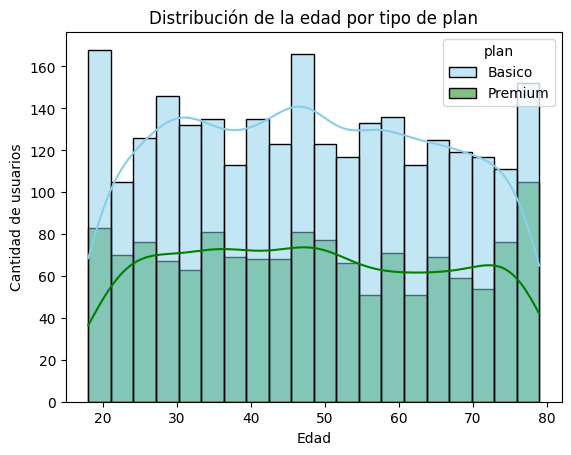

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x="age", hue="plan", palette=["skyblue", "green"], bins=20, kde=True)
plt.title("Distribución de la edad por tipo de plan")
plt.xlabel("Edad")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución aproximadamente uniforme, sin sesgo claro: las edades van de los 18 a los 79 años y hay cantidades parecidas en casi todos los rangos. Ambos planes siguen la misma forma, por lo que no existe un patrón entre edad y plan. El Básico tiene más usuarios en general, pero esa diferencia se mantiene en todas las edades.

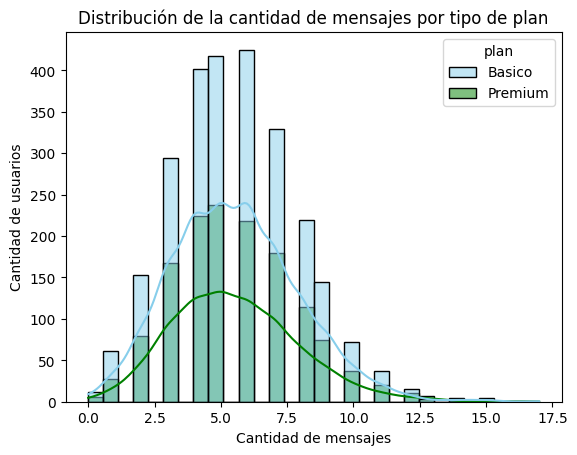

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue", "green"], bins=30, kde=True)
plt.title("Distribución de la cantidad de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Distribución casi simétrica, con una ligera cola a la derecha: la mayoría de los usuarios envía entre 4 y 7 mensajes, con el pico alrededor de 5 o 6, y pocos envían más de 12. Los usuarios Básico y Premium se comportan igual, con la misma forma y el mismo centro, por lo que no existe un patrón claro entre plan y cantidad de mensajes.

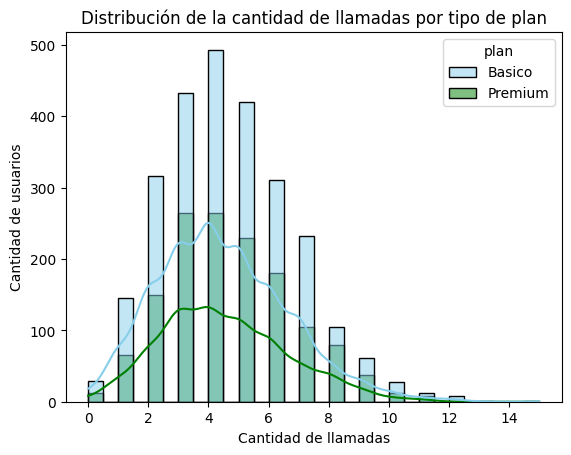

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue", "green"], bins=30, kde=True)
plt.title("Distribución de la cantidad de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución ligeramente sesgada a la derecha: la mayoría hace entre 3 y 6 llamadas, con el pico en 4, y hay pocos usuarios con más de 10. Ambos planes tienen la misma forma y el mismo centro, así que no existe un patrón entre plan y número de llamadas. Que el Básico tenga barras más altas se debe a que tiene más usuarios, no a que llame más.

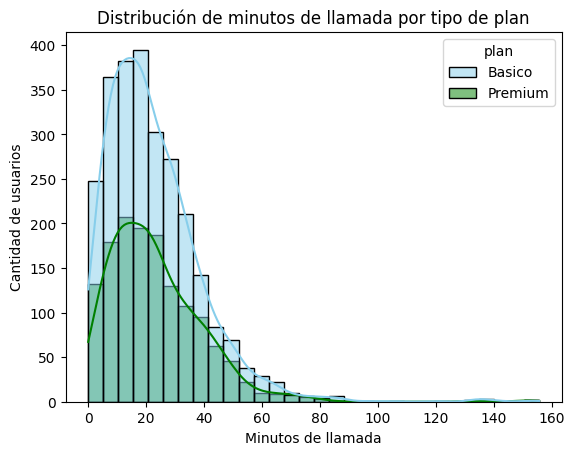

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue", "green"], bins=30, kde=True)
plt.title("Distribución de minutos de llamada por tipo de plan")
plt.xlabel("Minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución claramente sesgada a la derecha: la mayoría de los usuarios acumula entre 10 y 30 minutos, con el pico cerca de los 15 o 20, y una cola larga que llega hasta unos 150 minutos. Esos valores altos son pocos y probablemente casos extremos, que se revisarán en el siguiente paso. El comportamiento es similar en ambos planes, por lo que no existe un patrón claro por plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

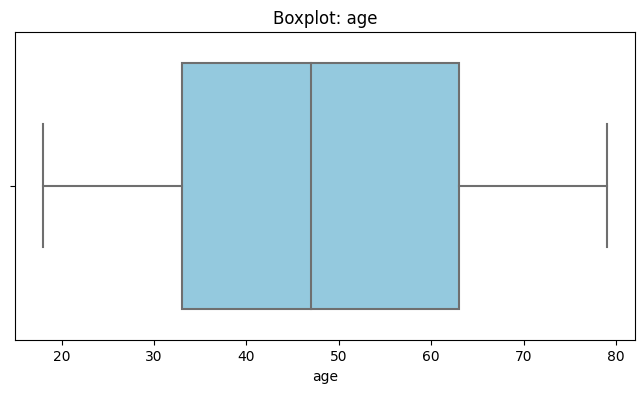

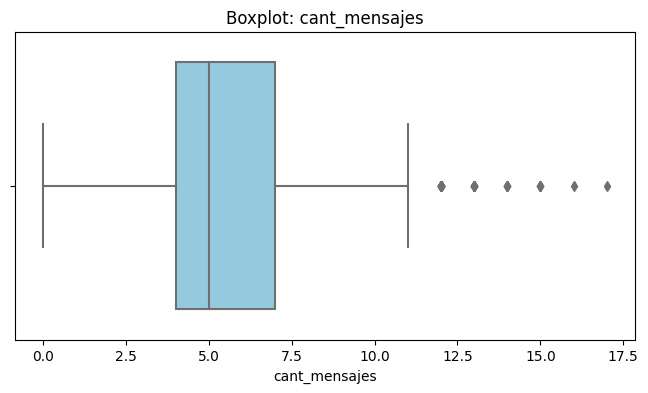

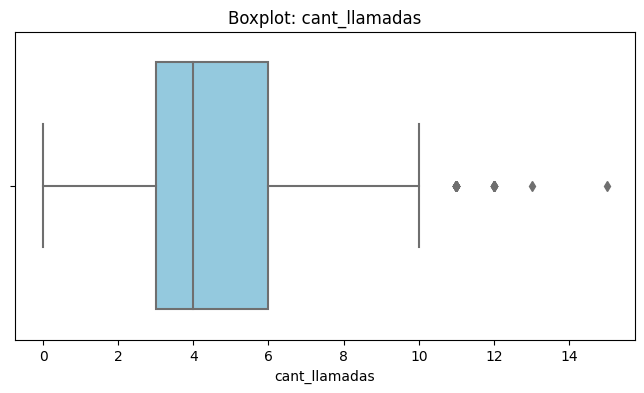

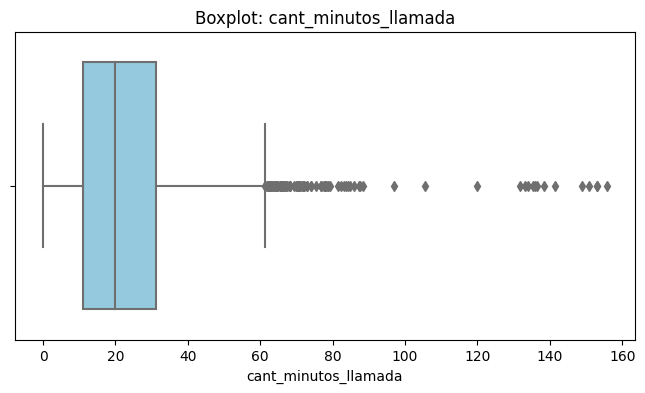

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color="skyblue")
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: no presenta outliers. Los bigotes llegan de 18 a 79 años sin puntos fuera de ellos, y la mediana ronda los 47 años, casi al centro de la caja, lo que confirma una distribución simétrica.
- cant_mensajes: presenta outliers por la derecha. La mayoría de los usuarios envía entre 4 y 7 mensajes (mediana de 5), y los puntos fuera del bigote van de 12 a 17 mensajes. Son pocos y cercanos al límite, así que representan usuarios que envían un poco más de lo habitual.
- cant_llamadas: presenta outliers por la derecha. La caja va de 3 a 6 llamadas (mediana de 4), y hay puntos aislados en 11, 12, 13 y 15 llamadas. Son valores altos, pero no exagerados frente al resto.
- cant_minutos_llamada: presenta muchos outliers por la derecha. La caja va de unos 11 a 31 minutos (mediana de unos 20), y los puntos fuera del bigote comienzan cerca de los 61 minutos y llegan hasta unos 155. Es la variable con más outliers y con los más alejados.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    n_outliers = ((user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)).sum()

    print(f"{col}: límite inferior = {limite_inferior:.2f}, límite superior = {limite_superior:.2f}, outliers = {n_outliers}")



cant_mensajes: límite inferior = -0.50, límite superior = 11.50, outliers = 46
cant_llamadas: límite inferior = -1.50, límite superior = 10.50, outliers = 30
cant_minutos_llamada: límite inferior = -19.04, límite superior = 61.32, outliers = 96


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Mantener los outliers. El límite superior es 11.50 y hay 46 outliers, es decir, solo el 1.15% de los 3,999 usuarios. El máximo es 17 mensajes, que está cerca del límite y es perfectamente posible para un usuario activo, así que no hay valores imposibles ni errores de captura. Eliminarlos quitaría información real de los usuarios más activos y casi no cambiaría la media (5.52) frente a la mediana (5).
- cant_llamadas: Mantener los outliers. El límite superior es 10.50 y hay 30 outliers, apenas el 0.75% de los usuarios. El máximo es 15 llamadas, un valor razonable y poco alejado del límite. La media (4.48) y la mediana (4) son casi iguales, por lo que estos valores no distorsionan el análisis.
- cant_minutos_llamada: Mantener los outliers. El límite superior es 61.32 minutos y hay 96 outliers, el 2.4% de los usuarios. Es la variable con valores más alejados: el máximo es 155.69 minutos, más de 2.5 veces el límite. Aun así es un valor plausible, porque se trata de minutos acumulados por un usuario, no de una sola llamada, y no hay nada imposible (el mínimo es 0 y no hay negativos). La media (22.84) es mayor que la mediana (19.74) por la cola derecha, así que al resumir esta variable conviene apoyarse en la mediana.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:

# Crear columna grupo_uso
user_profile["grupo_uso"] = "Alto uso"  # valor por defecto: el resto de casos

# Uso medio: llamadas < 10 y mensajes < 10
user_profile.loc[(user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10), "grupo_uso"] = "Uso medio"

# Bajo uso: llamadas < 5 y mensajes < 5 (se asigna al final para que tenga prioridad sobre Uso medio)
user_profile.loc[(user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5), "grupo_uso"] = "Bajo uso"



In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
user_profile["grupo_edad"] = "Adulto Mayor"  # valor por defecto: el resto de casos

# Adulto: age < 60
user_profile.loc[user_profile["age"] < 60, "grupo_edad"] = "Adulto"

# Joven: age < 30 (se asigna al final para que tenga prioridad sobre Adulto)
user_profile.loc[user_profile["age"] < 30, "grupo_edad"] = "Joven"

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

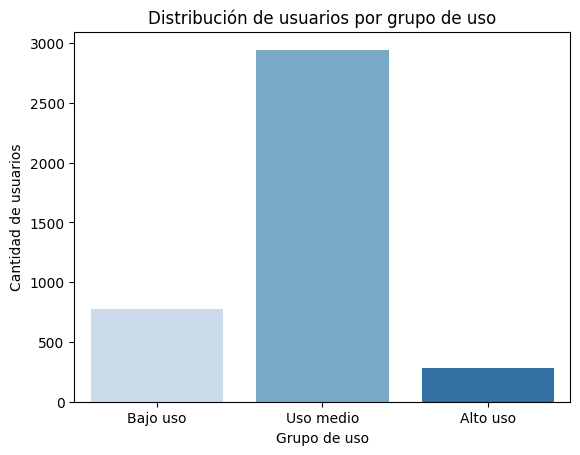

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso", order=["Bajo uso", "Uso medio", "Alto uso"], palette="Blues")
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

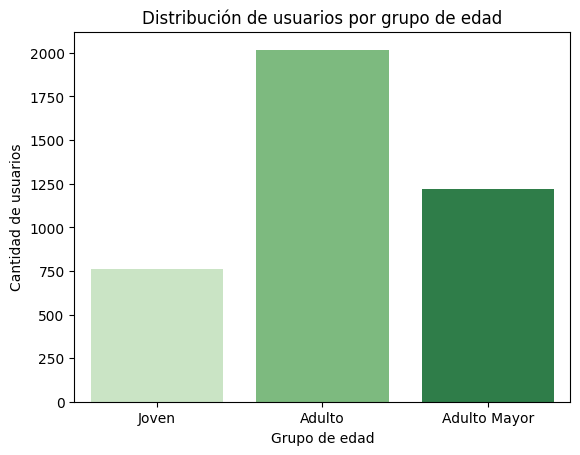

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad", order=["Joven", "Adulto", "Adulto Mayor"], palette="Greens")
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- **Contexto:** se analizaron 4,000 usuarios (`users`) y 40,000 registros de uso (`usage`), todos de 2024.
- **Hallazgo:** en `users`, 55 edades (1.4%) tenían el valor -999, 565 ciudades (14.1%) eran inválidas (469 nulos y 96 con "?") y 40 fechas de registro (1.0%) caían en 2026. En `usage`, 50 fechas (0.125%) eran nulas, y `duration` (55.2%) y `length` (44.7%) tenían nulos explicados por `type`: la duración solo aplica a llamadas y la longitud solo a mensajes.
- **Implicación:** los errores afectan a menos del 15% de cada columna y no comprometen el análisis. La edad se imputó con la mediana (47 años), las fechas imposibles y las ciudades inválidas quedaron como nulos, y los nulos de `duration` y `length` se conservaron porque no son datos faltantes.

🔍 **Segmentos por Edad**
- **Contexto:** la edad va de 18 a 79 años, sin outliers, y es igual en ambos planes.
- **Hallazgo:** Adulto (30-59) es el grupo más grande, con ~50% de los usuarios (~2,010). Le siguen Adulto Mayor (60+) con ~31% (~1,220) y Joven (<30) con ~19% (~760).
- **Implicación:** la base está concentrada en adultos de 30 a 59 años. La edad por sí sola no diferencia a los clientes de un plan u otro.

📊 **Segmentos por Nivel de Uso**
- **Contexto:** el usuario típico registra 5 mensajes, 4 llamadas y 19.7 minutos (medianas). Básico incluye 100 mensajes y 100 minutos; Premium, 500 mensajes y 600 minutos.
- **Hallazgo:** Uso medio concentra 74% de los usuarios (2,940), Bajo uso 19% (780) y Alto uso 7% (280). Los outliers son 46 en mensajes (1.15%), 30 en llamadas (0.75%) y 96 en minutos (2.4%), y se mantuvieron por ser consumos plausibles. El máximo es 17 mensajes, 15 llamadas y 155.7 minutos. Básico y Premium muestran la misma distribución en mensajes, llamadas y minutos.
- **Implicación:** casi todo el uso está muy por debajo de lo incluido en los planes. Solo el máximo de minutos (155.7) supera el límite de Básico, y ningún valor se acerca al de Premium. Los usuarios de Alto uso son el grupo con consumo más cercano a los límites.

➡️ **Esto sugiere que** Premium cuesta más del doble que Básico ( $25 vs $12 al mes) sin que sus usuarios llamen o envíen más. Los clientes pagan por capacidad que no usan, y el valor de Premium no se explica por el consumo de llamadas y mensajes. Los datos no incluyen consumo de GB, así que ese componente no se evaluó. El segmento más valioso por volumen es Uso medio (74%), y Alto uso (7%) es el de mayor consumo.

💡 **Recomendaciones**
- Crear un plan de entrada más económico, con límites cercanos al uso real, dirigido a Bajo uso y Uso medio.
- Revisar la propuesta de Premium: justificar su precio con beneficios distintos a minutos y mensajes, o ajustarlo, ya que el consumo es igual al de Básico.
- Ofrecer a Alto uso un paquete con minutos adicionales, porque es el grupo que se acerca a los límites de Básico.
- Validar la captura de datos para evitar valores centinela (-999, "?") y fechas futuras.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`